# cross encoder 리랭킹

**이 노트북에서 할 일**

1. 07절부터 쓰는 문서 청크 175개와 질문 30개를 불러와 개발 묶음을 가릅니다.
2. 05·06절 방법으로 개발 질문마다 후보 여덟 개를 만듭니다.
3. 질문과 후보 본문을 함께 읽는 리랭커로 후보의 자리를 다시 정합니다.
4. 후보 수를 둘로 줄여 후보 목록 밖 문서 청크가 어떻게 되는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 청크 1번과 질문 15번으로 모두 열여섯 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.

리랭커는 내 컴퓨터에서 도는 모델이라 요청 비용이 들지 않습니다.
처음 실행할 때 리랭커 파일 약 2.2GB를 내려받고 그다음부터는 받아 둔 파일을 씁니다.
실행 시간은 내려받기를 빼고 2분 안팎이며 리랭커 호출이 가장 오래 걸립니다.
리랭커를 만들고 쓰는 동안 메모리를 약 3GB 씁니다.
교재 출력은 메모리 3.8GB 환경에서 만들었고 최대 사용량은 약 3.1GB였습니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**강의와 실습 범위** — 강의 시간에는 2~3절과 7~9절을 읽습니다.
개발 묶음과 시험 묶음을 가르는 자리가 2절이고 리랭커를 준비하는 자리가 7절입니다.
8절이 실행 1이고 9절이 값 바꿔 보기입니다.
1·4~6·10절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 다섯 패키지를 고정한 판으로 설치합니다.
리랭커는 판 번호 `953dc6f6f85a`를 고정해 받습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

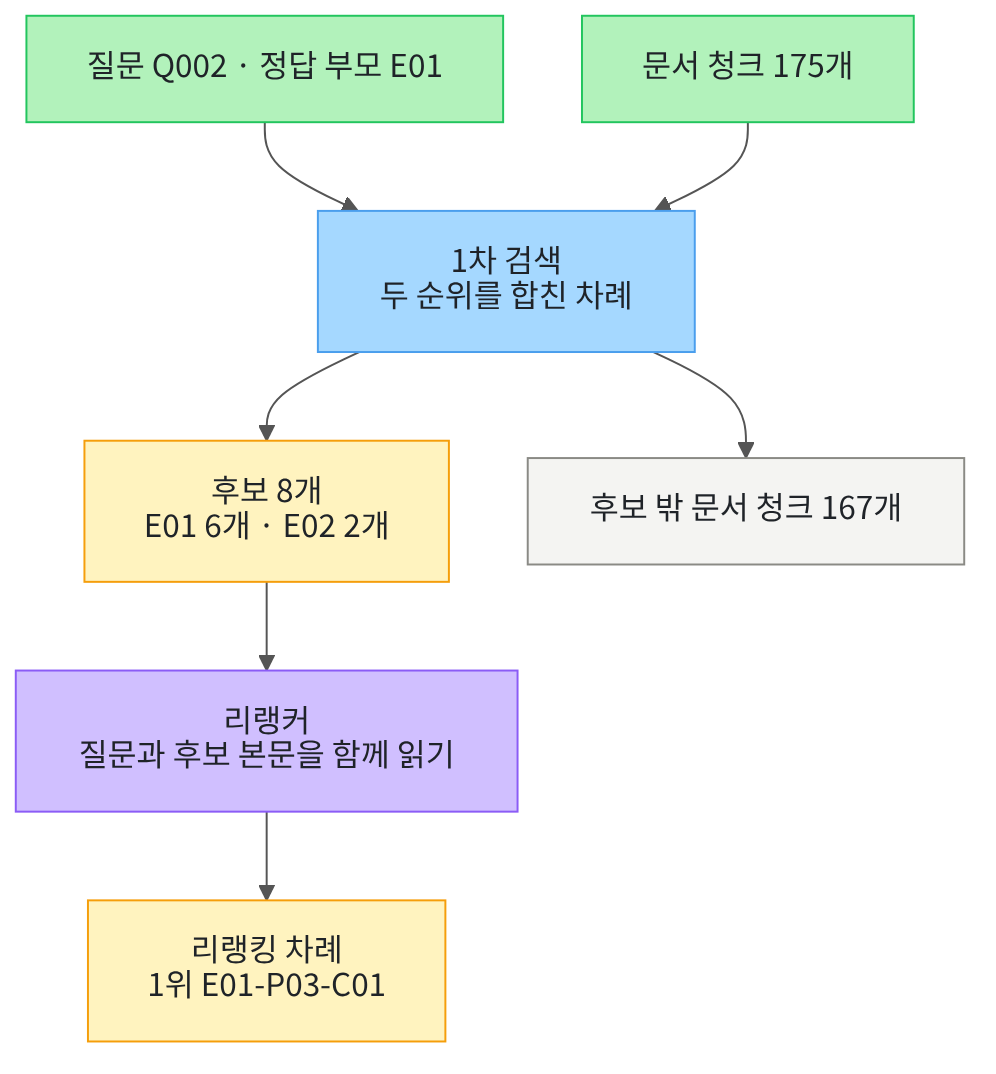

맨 위 초록 상자 두 개가 이 절이 쓰는 질문과 문서 청크 묶음입니다.
가운데 파란 상자가 05·06절에서 만든 검색이고 여기서 후보를 고릅니다.
왼쪽 노란 상자가 후보 8개이고 오른쪽 회색 상자가 후보 밖 문서 청크입니다.
보라 상자 리랭커로 가는 화살표는 왼쪽 갈래에만 있습니다.
맨 아래 노란 상자가 이 노트북 8절의 출력입니다.

## 1. 준비

첫 셀은 패키지 다섯 개를 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2" "sentence-transformers==6.0.1"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))
print("sentence-transformers:", version("sentence-transformers"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2
sentence-transformers: 6.0.1


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `sentence-transformers: 6.0.1`이 보입니다.
다섯 줄이 모두 보이면 다음 셀로 넘어갑니다.
05·06절 네 패키지에 리랭커를 부르는 패키지 하나가 늘었습니다.

다음 셀은 이 절에서 쓸 이름 여섯 개를 불러옵니다.
이름 `CrossEncoder`가 리랭커를 만드는 도구이고 이 챕터에서 처음 나옵니다.
환경 변수 `HF_HUB_DISABLE_PROGRESS_BARS`를 켜 두면 파일을 읽는 진행 막대가 나오지 않습니다.
환경 변수는 프로그램 밖에서 넘기는 설정 값이고 이름과 값이 모두 글입니다.

In [2]:
# 자료 읽기·제곱근·형태소 분석·임베딩·낱말 점수·리랭커에 쓸 이름을 불러옵니다
import json
import math
import os
import warnings

# 리랭커 파일을 읽을 때 나오는 진행 막대와 위젯 경고는 계산과 관계없어 화면에 내지 않습니다
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")

from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder

print("불러온 이름:", "json", "math", "Kiwi", "OpenAIEmbeddings", "BM25Okapi", "CrossEncoder")

불러온 이름: json math Kiwi OpenAIEmbeddings BM25Okapi CrossEncoder


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 여섯 개가 붙은 한 줄입니다.
앞의 다섯 이름은 01~06절에서 쓰던 이름과 같습니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~06절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 07절부터 쓰는 자료 두 벌을 읽습니다.
01~06절이 쓴 문서 12개와 질문 8개는 검색 원리를 짧게 보려고 만든 교육용 자료입니다.
이 절부터는 공개 PDF에서 뽑은 문서와 Ch 11 평가셋을 씁니다.

In [5]:
# 07절부터 쓰는 문서 파일과 질문 파일을 불러옵니다(01~06절과 다른 벌입니다)
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
문서 한 건을 쪽과 단락으로 잘라 둔 것이 문서 청크입니다.
그 문서 청크가 나온 원래 문서를 이 절에서는 부모 문서라고 부릅니다.
질문 파일의 정답 칸에는 부모 문서 ID가 들어 있습니다.

## 2. 개발 묶음과 시험 묶음 가르기

질문 파일에는 `split` 칸이 있고 값은 `dev`와 `test` 두 가지입니다.
Ch 11이 정한 약속은 개발 15문항으로 설정을 고르고 시험 15문항은 마지막에 한 번만 쓰는 것입니다.
이 절도 그 약속을 지켜 개발 묶음만 봅니다.
시험 묶음은 12절의 마지막 평가까지 열어 보지 않습니다.

In [6]:
# 질문 30개를 개발 묶음과 시험 묶음으로 나눕니다(Ch 11이 정해 둔 split 칸을 그대로 씁니다)
dev_queries = []
test_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
    else:
        test_queries.append(query)
print("개발 질문 수:", len(dev_queries))
print("시험 질문 수:", len(test_queries))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])
print("그 질문의 정답 부모 문서 ID:", dev_queries[0]["gold_doc_ids"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.
정답 칸 값은 `['E01']`처럼 목록입니다.
01~06절 질문 파일은 정답 문서 ID가 글 하나였고 이 파일은 목록입니다.

## 3. 이 절에서 쓸 값 정하기

01~06절에서 쓴 값 네 개를 그대로 다시 정합니다.
이름 `method_names`에 담을 두 이름이 이 절에서 견줄 두 단계입니다.

In [7]:
# 01~06절에서 쓴 값을 그대로 다시 정하고 이 절에서 견줄 두 단계 이름을 정합니다
similarity_top = 1
cutoff_values = [1, 2, 3]
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
method_names = ["1차 후보", "리랭킹"]
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("자르는 자리 세 가지:", cutoff_values)
print("남길 품사 표시:", keep_tags)
print("견줄 두 단계:", method_names)

코사인 유사도의 가장 큰 값: 1
자르는 자리 세 가지: [1, 2, 3]
남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
견줄 두 단계: ['1차 후보', '리랭킹']


**결과 읽기** — 줄 `견줄 두 단계: ['1차 후보', '리랭킹']`의 두 이름으로 기록을 나눕니다.
출력 줄 `자르는 자리 세 가지: [1, 2, 3]`은 01~06절과 같은 값입니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

다음 셀은 후보 수와 06절 합치기 설정을 정합니다.
후보 수 여덟 개는 리랭커가 볼 수 있는 문서 청크 수입니다.

In [8]:
# 후보 수와 06절 합치기 설정을 정합니다
candidate_count = 8
small_candidate_count = 2
rank_constant = 60
base_weight = 1.0
equal_weights = [base_weight, base_weight]
print("후보 수:", candidate_count)
print("줄여 볼 후보 수:", small_candidate_count)
print("순위 상수:", rank_constant)
print("같은 가중치:", equal_weights)

후보 수: 8
줄여 볼 후보 수: 2
순위 상수: 60
같은 가중치: [1.0, 1.0]


**결과 읽기** — `후보 수: 8`과 `줄여 볼 후보 수: 2`가 보입니다.
줄 `순위 상수: 60`과 `같은 가중치: [1.0, 1.0]`은 06절과 같은 값입니다.

## 4. 두 단계가 볼 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.
청크 ID로 부모 문서 ID와 글을 찾을 수 있게 짝도 함께 만들어 둡니다.

In [9]:
# 문서 청크마다 제목과 본문을 이어 붙이고 청크 ID·부모 문서 ID·글을 짝지어 둡니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
text_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
    text_by_chunk[chunk["chunk_id"]] = chunk_text
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])
print("첫 문서 청크 글:", chunk_texts[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01
첫 문서 청크 글: 미르시립도서관 이용 안내 미르시립도서관 이용 안내 미르시립도서관 2026년판 발행 2026. 3. 1.


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름은 부모 ID와 쪽 번호, 문서 청크 번호를 이은 것입니다.
출력 줄 `첫 문서 청크 글:` 뒤에는 제목과 본문이 이어져 있습니다.

다음 셀은 벡터 거리 쪽 재료를 만듭니다.
01~06절과 같은 모델과 같은 숫자 개수를 씁니다.

In [10]:
# 01~06절과 같은 모델로 문서 청크와 개발 질문을 벡터로 바꿉니다(임베딩 요청 16번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
query_vectors = []
for query in dev_queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175
질문 벡터 수: 15


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
출력 줄 `질문 벡터 수: 15`까지 나오면 임베딩 요청 열여섯 번이 끝났습니다.
이 노트북의 출력은 2026-09-18에 이 모델로 실행한 결과입니다.

다음 셀은 낱말 겹침 쪽 재료를 만들 함수를 준비합니다.
04~06절과 같은 함수이고 남길 품사 표시에 든 형태소만 남깁니다.

In [11]:
# 04~06절과 같은 형태소 분석기를 준비하고 남길 품사 표시에 든 형태소만 고르는 함수를 정의합니다
kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

**결과 읽기** — 정의 셀이라 출력이 없습니다.
분석기를 만드는 줄 `kiwi = Kiwi()`는 1초 안팎 걸립니다.

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [12]:
# 문서 청크마다 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04~06절과 같은 코드)
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 문서 청크 하나에 든 낱말 수입니다.
01~06절 교육용 문서보다 한 건이 길어 나온 값입니다.

## 5. 1차 검색 함수 다시 만들기

01절에서 만든 함수 네 개를 같은 코드로 다시 정의합니다.
점곱과 길이로 코사인 유사도를 내고 그 값을 거리로 바꿉니다.

In [13]:
# 두 벡터의 점곱(같은 자리 숫자끼리 곱해 모두 더한 값)을 반환하는 함수를 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 벡터의 길이를 내는 함수입니다.

In [14]:
# 벡터의 길이(자기 자신과의 점곱에 제곱근을 씌운 값)를 반환하는 함수를 정의합니다
def vector_length(vector):
    # 자기 자신과의 점곱은 숫자마다 제곱해 더한 값입니다
    squared_sum = dot_product(vector, vector)
    # math.sqrt(수)는 제곱근을 반환합니다
    return math.sqrt(squared_sum)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 두 벡터의 코사인 유사도를 내는 함수입니다.

In [15]:
# 두 벡터의 코사인 유사도(점곱을 두 길이의 곱으로 나눈 값)를 반환하는 함수를 정의합니다
def cosine_similarity(first, second):
    dot = dot_product(first, second)
    # 두 길이를 곱한 값으로 나누면 화살표 길이와 관계없이 방향만 비교합니다
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 유사도를 거리로 바꾸는 함수입니다.
유사도는 클수록 가깝고 거리는 작을수록 가깝습니다.

In [16]:
# 코사인 유사도를 코사인 거리로 바꾸는 함수를 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    # 가장 큰 값 1에서 빼면 값이 작을수록 가까운 자가 됩니다
    return similarity_top - similarity

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 질문 하나를 문서 청크 모두와 재어 순위를 만듭니다.
05·06절과 같은 코드이고 값 칸 이름은 `거리`입니다.
문서 대신 문서 청크를 재므로 키 이름만 `chunk_id`로 바뀌었습니다.

In [17]:
# 질문 벡터 하나를 문서 청크 모두와 재어 거리가 작은 순서로 순위 목록을 만듭니다(05·06절과 같은 코드)
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 낱말 겹침 쪽 순위 함수입니다. 05·06절과 같은 코드입니다.

In [18]:
# 질문 하나를 낱말 겹침으로 재어 점수가 큰 순서로 순위 목록을 만듭니다(05·06절과 같은 코드)
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
값 칸 이름은 `점수`입니다. 앞 함수의 `거리`와 뜻이 반대라 이름을 갈랐습니다.

다음 셀은 순위 목록에서 문서 청크 ID만 차례로 모으는 함수입니다.

In [19]:
# 순위 목록에서 문서 청크 ID를 차례로 모으고 처음 나온 것만 남깁니다(06절 unique_doc_ids와 같은 모양)
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
06절 함수와 같은 모양이고 보는 키만 `chunk_id`입니다.

다음 셀은 목록에서 찾는 ID가 몇 번째 자리인지 세는 함수입니다.
이 코드는 Ch 11 01절에서 정답 문서의 자리를 셀 때 만든 것과 같습니다.
이 절에서는 후보 한 건의 자리를 찾을 때도 씁니다.

In [20]:
# ID 목록에서 찾는 ID가 몇 번째 자리인지 셉니다(Ch 11 01절과 같은 코드)
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 정의 셀이라 출력이 없습니다.
찾는 ID가 목록에 없으면 0이 나옵니다.

다음 셀은 06절에서 만든 합치기 함수입니다. 자리 번호만 보고 몫을 냅니다.

In [21]:
# 순위 목록 여러 개를 받아 문서 청크마다 자리 몫을 더한 합친 점수를 냅니다(06절과 같은 코드)
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 합친 점수가 큰 순서로 문서 청크 ID 목록을 만듭니다.

In [22]:
# 합친 점수가 큰 순서로 문서 청크 ID 목록을 만듭니다(06절과 같은 코드)
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.

## 6. 후보 목록 만들기

개발 질문마다 두 순위를 만들어 합치고 앞자리 여덟 개를 후보로 자릅니다.
06절에서 합친 순위가 두 방법보다 나아지지는 않았습니다.
여기서 합친 순위를 쓰는 까닭은 두 방법이 앞에 둔 문서 청크를 후보에 함께 담기 위해서입니다.
어느 1차 검색이 더 나은지는 이 절에서 재지 않습니다.

In [23]:
# 개발 질문마다 두 순위를 합쳐 전체 차례를 만들고 앞자리 여덟 개를 후보로 자릅니다
all_chunk_count = len(chunk_ids)
fused_lists = []
candidate_lists = []
for query_index in range(len(dev_queries)):
    distance_hits = rank_by_distance(query_vectors[query_index], all_chunk_count)
    score_hits = rank_by_bm25(dev_queries[query_index]["question"], all_chunk_count)
    ranking_list = [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]
    fused_ids = fuse_rank(ranking_list, equal_weights)
    fused_lists.append(fused_ids)
    candidate_lists.append(fused_ids[:candidate_count])
print("만든 후보 목록 수:", len(candidate_lists))
print("후보 목록 하나의 문서 청크 수:", len(candidate_lists[0]))

만든 후보 목록 수: 15
후보 목록 하나의 문서 청크 수: 8


**결과 읽기** — `만든 후보 목록 수: 15`와 `후보 목록 하나의 문서 청크 수: 8`이 보입니다.
개발 질문 하나에 후보 목록 하나가 만들어졌습니다.
이름 `fused_lists`에는 자르기 전 전체 차례가 그대로 남아 있습니다.

다음 셀은 문서 청크 ID 목록을 부모 문서 ID 목록으로 바꾸는 함수입니다.
질문 파일의 정답이 부모 문서 ID라 지표를 재기 전에 이 단계가 필요합니다.

In [24]:
# 문서 청크 ID 목록을 부모 문서 ID 목록으로 바꾸고 처음 나온 것만 남깁니다
def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
후보 여덟 개가 같은 부모에서 나오면 목록 하나만 남습니다.

## 7. 리랭커 준비

리랭커는 질문과 후보 본문을 한 쌍으로 묶어 함께 읽는 모델입니다.
1차 검색은 질문과 문서 청크를 따로 벡터로 만들어 견주었습니다.
쌍으로 읽으면 질문의 낱말과 본문의 낱말을 같은 자리에서 볼 수 있습니다.
대신 후보마다 한 번씩 모델을 지나야 해서 문서 청크 175개 전체에는 쓰기 어렵습니다.

In [25]:
# 질문과 후보 본문을 함께 읽는 리랭커를 판 번호를 고정해 준비합니다
reranker_name = "BAAI/bge-reranker-v2-m3"
reranker_revision = "953dc6f6f85a1b2dbfca4c34a2796e7dde08d41e"
reranker_max_length = 256
reranker = CrossEncoder(
    reranker_name,
    revision=reranker_revision,
    max_length=reranker_max_length,
    device="cpu",
)
print("리랭커 이름:", reranker_name)
print("리랭커 판 번호 앞 열두 글자:", reranker_revision[:12])
print("한 쌍에서 읽는 최대 조각 수:", reranker.max_seq_length)

리랭커 이름: BAAI/bge-reranker-v2-m3
리랭커 판 번호 앞 열두 글자: 953dc6f6f85a
한 쌍에서 읽는 최대 조각 수: 256


**결과 읽기** — 출력 맨 위의 영문 알림은 계정을 밝히지 않고 파일을 받았다는 뜻입니다.
줄 `리랭커 판 번호 앞 열두 글자: 953dc6f6f85a`가 그다음에 보입니다.
줄 `한 쌍에서 읽는 최대 조각 수: 256`은 한 쌍에서 앞쪽 조각만 읽는다는 뜻입니다.
처음 실행할 때는 이 셀에서 파일 약 2.2GB를 내려받아 몇 분이 걸립니다.
판 번호를 고정하면 다음에 실행해도 같은 파일을 씁니다.

다음 셀은 리랭커에 넣을 쌍 목록을 만드는 함수입니다.

In [26]:
# 질문 하나와 후보 본문을 짝지어 리랭커에 넣을 쌍 목록을 만듭니다
def make_pairs(question, found_chunk_ids):
    pairs = []
    for chunk_id in found_chunk_ids:
        # 쌍 하나는 (질문, 후보 본문) 모양의 튜플입니다
        pairs.append((question, text_by_chunk[chunk_id]))
    return pairs

**결과 읽기** — 정의 셀이라 출력이 없습니다.
쌍 하나에 질문 글과 후보 본문이 함께 들어갑니다.

다음 셀은 쌍마다 점수를 받아 다시 정렬하는 함수입니다.
함수 `predict()`가 주는 값은 넘파이 배열이라 `tolist()`로 파이썬 목록으로 바꿉니다.
점수는 클수록 관련 있는 값이라 04~06절처럼 음수를 붙여 정렬합니다.

In [27]:
# 쌍마다 리랭킹 점수를 받아 점수가 큰 순서로 후보를 다시 정렬합니다
def rerank(question, found_chunk_ids):
    pairs = make_pairs(question, found_chunk_ids)
    scores = reranker.predict(pairs, show_progress_bar=False)
    # predict가 주는 값은 넘파이 배열이라 tolist()로 파이썬 목록으로 바꿉니다
    score_list = scores.tolist()
    ranked_pairs = []
    for i in range(len(found_chunk_ids)):
        ranked_pairs.append((0 - score_list[i], found_chunk_ids[i]))
    hit_list = []
    for pair in sorted(ranked_pairs):
        hit_list.append({"chunk_id": pair[1], "리랭킹 점수": round(0 - pair[0], 4)})
    return hit_list

**결과 읽기** — 정의 셀이라 출력이 없습니다.
설치판 소스 확인: 값이 하나인 리랭커는 점수를 0과 1 사이로 눌러 줍니다.
그래서 이 절은 그 값을 리랭킹 점수라고 부르고 확률로 읽지 않습니다.

## 8. 실행 1 — 후보 여덟 개를 다시 정렬하기

개발 질문 하나를 골라 1차 검색이 만든 후보를 먼저 봅니다.
실행 전에 예상해 봅니다. 후보 여덟 개의 부모 문서는 한두 건일 것입니다.

In [28]:
# 실행 1: 개발 질문 하나를 골라 1차 검색이 만든 후보 여덟 개를 자리 차례로 봅니다
example_index = 1
example_query = dev_queries[example_index]
example_candidates = candidate_lists[example_index]
print("고른 질문:", example_query["qid"], "|", example_query["question"])
print("그 질문의 정답 부모 문서 ID:", example_query["gold_doc_ids"])
print("1차 자리 | 문서 청크 ID | 부모 문서 ID")
for position in range(candidate_count):
    chunk_id = example_candidates[position]
    print(position + 1, "|", chunk_id, "|", parent_by_chunk[chunk_id])
print("후보의 부모 문서 차례:", parent_ids_of(example_candidates))
print("후보 밖 문서 청크 수:", all_chunk_count - candidate_count)

고른 질문: Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
그 질문의 정답 부모 문서 ID: ['E01']
1차 자리 | 문서 청크 ID | 부모 문서 ID
1 | E01-P03-C02 | E01
2 | E01-P04-C06 | E01
3 | E01-P03-C01 | E01
4 | E01-P03-C08 | E01
5 | E01-P03-C04 | E01
6 | E01-P03-C06 | E01
7 | E02-P02-C05 | E02
8 | E02-P03-C02 | E02
후보의 부모 문서 차례: ['E01', 'E02']
후보 밖 문서 청크 수: 167


**결과 읽기** — 라벨 줄 아래 여덟 줄 가운데 앞 여섯 줄의 부모가 `E01`입니다.
줄 `후보의 부모 문서 차례: ['E01', 'E02']`에 부모 두 건이 있습니다.
정답 부모 `E01`이 후보 안에 있고 차례로도 앞입니다.
출력 줄 `후보 밖 문서 청크 수: 167`이 리랭커가 보지 못하는 문서 청크 수입니다.

다음 셀은 같은 후보 여덟 개를 리랭커에 넣습니다.
실행 전에 예상해 봅니다. 문서 청크 여덟 개는 그대로이고 자리만 바뀔 것입니다.

In [29]:
# 같은 후보 여덟 개를 리랭커에 넣어 자리를 다시 정합니다
example_ranked = rerank(example_query["question"], example_candidates)
example_ranked_ids = unique_chunk_ids(example_ranked)
print("리랭킹 자리 | 문서 청크 ID | 1차 자리 | 리랭킹 점수")
for position in range(len(example_ranked)):
    row = example_ranked[position]
    first_place = find_gold_rank(example_candidates, [row["chunk_id"]])
    print(position + 1, "|", row["chunk_id"], "|", first_place, "|", row["리랭킹 점수"])
print("리랭킹 뒤 부모 문서 차례:", parent_ids_of(example_ranked_ids))
print("리랭킹 전후 문서 청크가 같은 묶음인가:", sorted(example_candidates) == sorted(example_ranked_ids))

리랭킹 자리 | 문서 청크 ID | 1차 자리 | 리랭킹 점수
1 | E01-P03-C01 | 3 | 0.2246
2 | E01-P03-C02 | 1 | 0.003
3 | E01-P03-C08 | 4 | 0.0003
4 | E01-P04-C06 | 2 | 0.0003
5 | E01-P03-C04 | 5 | 0.0003
6 | E01-P03-C06 | 6 | 0.0002
7 | E02-P03-C02 | 8 | 0.0001
8 | E02-P02-C05 | 7 | 0.0
리랭킹 뒤 부모 문서 차례: ['E01', 'E02']
리랭킹 전후 문서 청크가 같은 묶음인가: True


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1 | E01-P03-C01 | 3 | 0.2246`입니다.
1차 자리 3이던 문서 청크가 리랭킹 뒤 1위로 올라왔습니다.
둘째 줄 `2 | E01-P03-C02 | 1 | 0.003`이 1차 1위였던 문서 청크입니다.
출력 줄 `리랭킹 전후 문서 청크가 같은 묶음인가: True`는 여덟 개가 그대로라는 뜻입니다.

3·4·5위는 소수 넷째 자리까지 같아 보이지만 정렬은 반올림 전 값으로 했습니다.
그 차례는 결과로 읽지 않습니다.

질문은 빌릴 수 있는 권수와 기간을 함께 묻습니다.
자료 파일에서 확인한 사실이고 이 셀은 두 본문을 출력하지 않았습니다.
리랭킹 1위로 올라온 문서 청크에는 권수에 해당하는 글이 있습니다.
1차 1위였던 문서 청크에는 기간에 해당하는 글이 있습니다.
어느 쪽이 더 맞는 답인지는 이 절에서 판정하지 않습니다.

## 9. 값 바꿔 보기 — 후보 수를 둘로 줄이기

바꿀 값은 후보 수 하나입니다.
질문과 리랭커, 1차 검색은 그대로 둡니다.
실행 전에 예상해 봅니다. 앞에서 1위였던 문서 청크가 후보에 없을 것입니다.

In [30]:
# 값 바꿔 보기: 같은 질문과 같은 리랭커에서 후보 수만 둘로 줄입니다
small_candidates = fused_lists[example_index][:small_candidate_count]
small_ranked = rerank(example_query["question"], small_candidates)
best_chunk_id = example_ranked[0]["chunk_id"]
print("쓴 후보 수:", small_candidate_count)
print("리랭킹 자리 | 문서 청크 ID | 리랭킹 점수")
for position in range(len(small_ranked)):
    print(position + 1, "|", small_ranked[position]["chunk_id"], "|", small_ranked[position]["리랭킹 점수"])
print("후보 여덟 개의 리랭킹 1위:", best_chunk_id)
print("그 문서 청크가 후보 둘에 있는가:", best_chunk_id in small_candidates)
print("그 문서 청크의 1차 자리:", find_gold_rank(fused_lists[example_index], [best_chunk_id]))

쓴 후보 수: 2
리랭킹 자리 | 문서 청크 ID | 리랭킹 점수
1 | E01-P03-C02 | 0.003
2 | E01-P04-C06 | 0.0003
후보 여덟 개의 리랭킹 1위: E01-P03-C01
그 문서 청크가 후보 둘에 있는가: False
그 문서 청크의 1차 자리: 3


**결과 읽기** — 줄 `그 문서 청크가 후보 둘에 있는가: False`가 이 절의 요점입니다.
후보 여덟 개에서 1위였던 `E01-P03-C01`의 1차 자리가 3이라 앞 둘에 들지 못했습니다.
그래서 후보 둘의 리랭킹 1위는 `E01-P03-C02`입니다.
리랭커는 받은 후보에만 점수를 내고 목록 밖 문서 청크를 끌어오지 못합니다.

후보 수를 줄이면 리랭커가 볼 수 있는 범위도 줄어듭니다.
후보 수와 리랭커를 여러 벌로 견주는 일은 08절에서 합니다.

## 10. 개발 질문 열다섯 개로 두 단계 견주기

질문 하나로는 두 단계의 차이를 말할 수 없습니다.
Ch 11과 01~06절에서 쓴 지표 함수 두 개를 그대로 이어 씁니다.

In [31]:
# 문서 ID 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다(Ch 11 02절과 같은 코드)
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
자르는 자리까지 자른 목록에 정답 부모가 있으면 1.0이 나옵니다.

다음 셀은 질문마다 낸 점수를 같은 무게로 평균하는 함수입니다.

In [32]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다(Ch 11 02절과 같은 코드)
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 문서 청크 ID 목록 하나를 받아 기록 한 줄을 만듭니다.
목록을 부모 문서 ID로 바꾼 뒤에 자리와 재현율을 잽니다.

In [33]:
# 문서 청크 ID 목록 하나를 받아 부모 문서 ID로 바꾼 뒤 기록 한 줄을 만듭니다
def score_one(query_index, method_name, found_chunk_ids):
    query = dev_queries[query_index]
    found_ids = parent_ids_of(found_chunk_ids)
    row = {"방법": method_name, "질문": query["qid"], "난이도": query["tier"]}
    row["1위 문서 청크"] = found_chunk_ids[0]
    row["정답 자리"] = find_gold_rank(found_ids, query["gold_doc_ids"])
    for cutoff in cutoff_values:
        row["자리 " + str(cutoff)] = recall_at(found_ids, query["gold_doc_ids"], cutoff)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `1위 문서 청크`에는 바꾸기 전 목록의 첫 문서 청크 ID를 담습니다.

## 두 단계를 모두 재기

개발 질문 열다섯 개를 두 단계로 모두 잽니다.
1차 후보는 앞에서 만들어 두었고 리랭킹은 질문마다 한 번씩 부릅니다.

In [34]:
# 개발 질문 열다섯 개를 두 단계로 모두 재어 기록 줄을 담습니다(리랭커 호출 열다섯 번)
score_rows = []
for method_name in method_names:
    for query_index in range(len(dev_queries)):
        # 두 단계가 갈리는 곳은 이 조건 두 갈래뿐입니다
        if method_name == method_names[0]:
            found_chunk_ids = candidate_lists[query_index]
        else:
            ranked = rerank(dev_queries[query_index]["question"], candidate_lists[query_index])
            found_chunk_ids = unique_chunk_ids(ranked)
        score_rows.append(score_one(query_index, method_name, found_chunk_ids))
print("담은 기록 줄 수:", len(score_rows))

담은 기록 줄 수: 30


**결과 읽기** — `담은 기록 줄 수: 30`이 보입니다.
개발 질문 열다섯 개에 단계 두 가지를 곱한 수입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [35]:
# 방법·질문·난이도·1위 문서 청크·정답 자리·자리 1·자리 3을 라벨 줄 아래에 차례로 출력합니다
print("방법 | 질문 | 난이도 | 1위 문서 청크 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율")
for row in score_rows:
    print(row["방법"], "|", row["질문"], "|", row["난이도"], "|", row["1위 문서 청크"], "|", row["정답 자리"], "|", row["자리 1"], "|", row["자리 3"])

방법 | 질문 | 난이도 | 1위 문서 청크 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율
1차 후보 | Q001 | easy | E01-P02-C04 | 1 | 1.0 | 1.0
1차 후보 | Q002 | easy | E01-P03-C02 | 1 | 1.0 | 1.0
1차 후보 | Q003 | easy | E01-P03-C04 | 1 | 1.0 | 1.0
1차 후보 | Q004 | easy | E01-P04-C04 | 1 | 1.0 | 1.0
1차 후보 | Q005 | easy | E01-P03-C08 | 1 | 1.0 | 1.0
1차 후보 | Q037 | medium | M01-P03-C02 | 1 | 1.0 | 1.0
1차 후보 | Q038 | medium | M01-P02-C02 | 1 | 1.0 | 1.0
1차 후보 | Q039 | medium | M01-P05-C05 | 1 | 1.0 | 1.0
1차 후보 | Q040 | medium | M01-P02-C05 | 1 | 1.0 | 1.0
1차 후보 | Q041 | medium | M01-P04-C02 | 1 | 1.0 | 1.0
1차 후보 | Q085 | hard | H01-P03-C02 | 1 | 1.0 | 1.0
1차 후보 | Q086 | hard | H01-P03-C02 | 1 | 1.0 | 1.0
1차 후보 | Q087 | hard | H01-P07-C02 | 1 | 1.0 | 1.0
1차 후보 | Q088 | hard | H01-P05-C02 | 1 | 1.0 | 1.0
1차 후보 | Q089 | hard | H01-P04-C01 | 1 | 1.0 | 1.0
리랭킹 | Q001 | easy | E01-P02-C04 | 1 | 1.0 | 1.0
리랭킹 | Q002 | easy | E01-P03-C01 | 1 | 1.0 | 1.0
리랭킹 | Q003 | easy | E01-P03-C04 | 1 | 1.0 | 1.0
리랭킹 | Q004 | easy | E01-P04-C04 | 1 | 1.0

**결과 읽기** — 라벨 줄 아래 앞 열다섯 줄이 1차 후보이고 그다음 열다섯 줄이 리랭킹입니다.
정답 자리 칸은 서른 줄이 모두 `1`입니다.
자리 1 재현율과 자리 3 재현율도 서른 줄이 모두 `1.0`입니다.
칸 `1위 문서 청크`는 줄마다 다릅니다.

다음 셀은 자르는 자리마다 질문 평균 재현율을 견줍니다.

In [36]:
# 두 단계의 질문 평균 재현율을 자르는 자리마다 견줍니다
print("방법 | 자르는 자리 | 질문 평균 재현율")
for method_name in method_names:
    picked = []
    for row in score_rows:
        if row["방법"] == method_name:
            picked.append(row)
    for cutoff in cutoff_values:
        picked_scores = []
        for row in picked:
            picked_scores.append(row["자리 " + str(cutoff)])
        print(method_name, "|", cutoff, "|", mean_score(picked_scores))

방법 | 자르는 자리 | 질문 평균 재현율
1차 후보 | 1 | 1.0
1차 후보 | 2 | 1.0
1차 후보 | 3 | 1.0
리랭킹 | 1 | 1.0
리랭킹 | 2 | 1.0
리랭킹 | 3 | 1.0


**결과 읽기** — 라벨 줄 아래 여섯 줄이 모두 `1.0`입니다.
1차 후보가 이미 정답 부모를 자리 1에 두어 더 올라갈 자리가 없습니다.
부모 문서가 6건뿐이라 부모 차례도 길지 않습니다.
이런 자리에서는 재현율로 두 단계를 가를 수 없습니다.

다음 셀은 두 단계의 1위 문서 청크를 질문마다 견줍니다.

In [37]:
# 두 단계의 1위 문서 청크를 질문마다 견주고 달라진 줄만 출력합니다
dev_count = len(dev_queries)
changed_count = 0
print("질문 | 1차 1위 문서 청크 | 리랭킹 1위 문서 청크")
for query_index in range(dev_count):
    before_row = score_rows[query_index]
    after_row = score_rows[dev_count + query_index]
    if before_row["1위 문서 청크"] != after_row["1위 문서 청크"]:
        changed_count = changed_count + 1
        print(before_row["질문"], "|", before_row["1위 문서 청크"], "|", after_row["1위 문서 청크"])
print("1위 문서 청크가 바뀐 질문 수:", changed_count)

질문 | 1차 1위 문서 청크 | 리랭킹 1위 문서 청크
Q002 | E01-P03-C02 | E01-P03-C01
Q039 | M01-P05-C05 | M01-P03-C01
Q087 | H01-P07-C02 | H01-P07-C03
1위 문서 청크가 바뀐 질문 수: 3


**결과 읽기** — 줄 `1위 문서 청크가 바뀐 질문 수: 3`이 보입니다.
바뀐 질문은 `Q002`와 `Q039`, `Q087` 셋입니다.
세 줄 모두 1차 1위와 리랭킹 1위의 부모 문서 ID 앞 세 글자가 같습니다.
재현율은 그대로였지만 앞자리에 놓인 문서 청크는 바뀌었습니다.

## 정리

1. 1차 검색으로 후보 여덟 개를 만들고 리랭커로 자리를 다시 정했습니다.
2. 후보 수를 둘로 줄이니 앞에서 1위였던 문서 청크가 결과에 나오지 않았습니다.
3. 이번 실행에서 정답 부모 자리는 두 단계 모두 열다섯 질문이 1이었습니다.

08절에서는 같은 개발 질문에서 후보 수와 리랭커를 여러 벌로 바꿔 가며 견줍니다.